# A Dead by Daylight adatainak elemzése


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px


DATA = Path("dataset")
DATA_URL = "https://raw.githubusercontent.com/nemethbalu06-svg/Python-projekt/main/dataset"
RARITIES = {
    "Common": "Gyakori",
    "Uncommon": "Nem gyakori",
    "Rare": "Ritka",
    "Very Rare": "Nagyon ritka",
    "Ultra Rare": "Rendkívül ritka",
}


def read(name):
    filename = f"{name}.csv"
    source = DATA / filename if DATA.is_dir() else f"{DATA_URL}/{filename}"
    return pd.read_csv(source)


def counts(data, column, label):
    return data[column].map(RARITIES).value_counts().rename_axis(label).reset_index(name="Darabszám")

## Karakterek

Hány gyilkos és túlélő szerepel az adatokban?

Szerepkör  Darabszám
  Gyilkos         22
   Túlélő         24


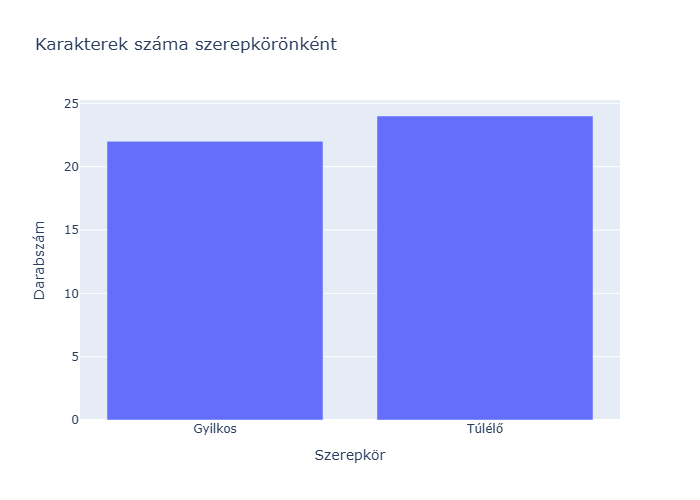

In [2]:
killers = read("killers")
survivors = read("survivors")
characters = pd.DataFrame({
    "Szerepkör": ["Gyilkos", "Túlélő"],
    "Darabszám": [killers["killer"].nunique(), survivors["survivor"].nunique()],
})
print(characters.to_string(index=False))
px.bar(characters, x="Szerepkör", y="Darabszám", title="Karakterek száma szerepkörönként").show()

## Képességek

Az általános képességek külön szerepelnek a diagramon. A karakterenkénti átlagba csak a karakterhez tartozó képességek számítanak bele.

Átlagos képességszám karakterenként (Gyilkos): 3.00
Átlagos képességszám karakterenként (Túlélő): 3.00


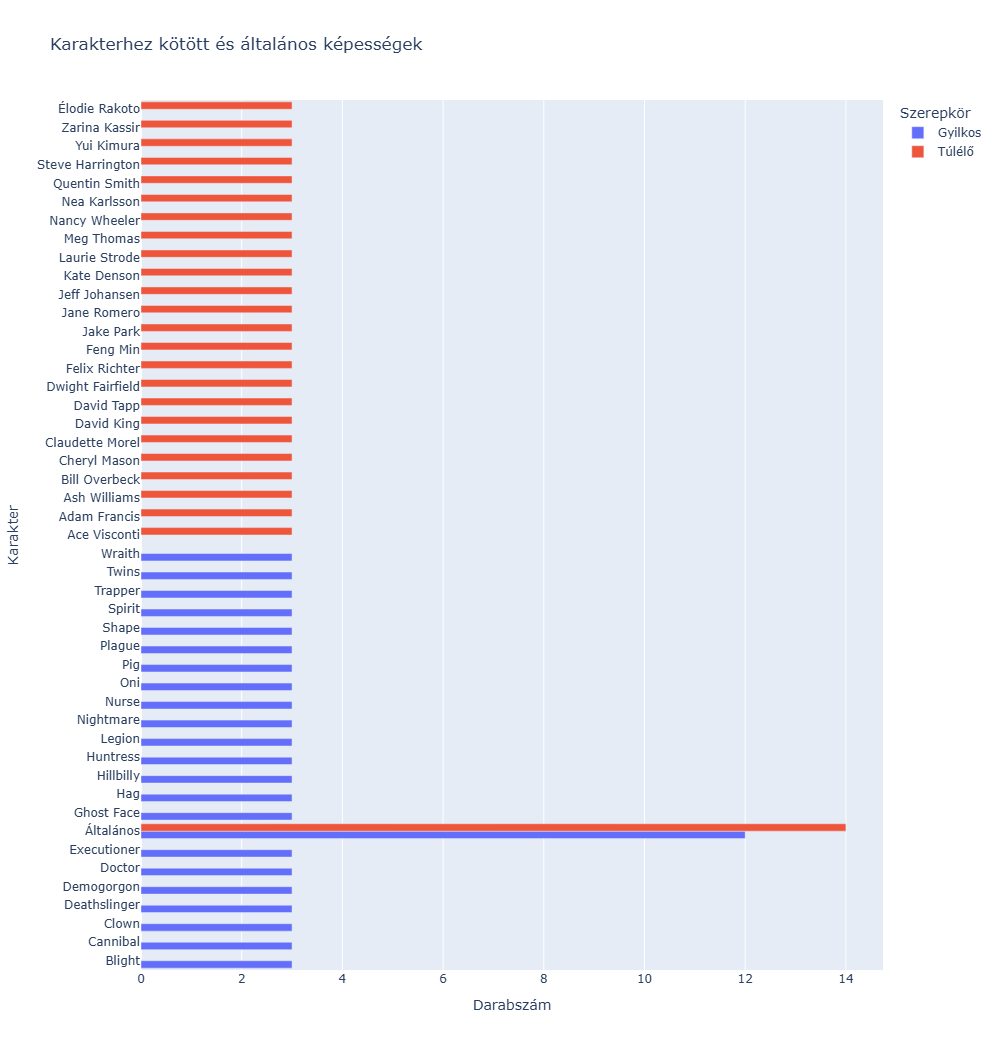

In [3]:
perk_counts = []
for role, label, roster in [("killer", "Gyilkos", killers), ("survivor", "Túlélő", survivors)]:
    perks = read(f"{role}Perks")
    totals = perks.groupby(role)["perk"].nunique()
    character_totals = totals.reindex(roster[role], fill_value=0)
    perk_counts.append(totals.rename(index={"General": "Általános"}).rename_axis("Karakter").reset_index(name="Darabszám")
                       .assign(Szerepkör=label))
    average = np.mean(character_totals.to_numpy())
    print(f"Átlagos képességszám karakterenként ({label}): {average:.2f}")
perks_by_character = pd.concat(perk_counts, ignore_index=True)
px.bar(perks_by_character, x="Darabszám", y="Karakter", title="Karakterhez kötött és általános képességek",
       color="Szerepkör", barmode="group", height=1050).show()

### Karakterenkénti képességek szóródása és eloszlása (boxplot)

A diagram a saját képességek számát hasonlítja össze a gyilkosok és a túlélők között. Az általános képességek nem számítanak bele. Ebben az adatállományban minden karakterhez három saját képesség tartozik, ezért a két doboz egy-egy vonallá esik össze.

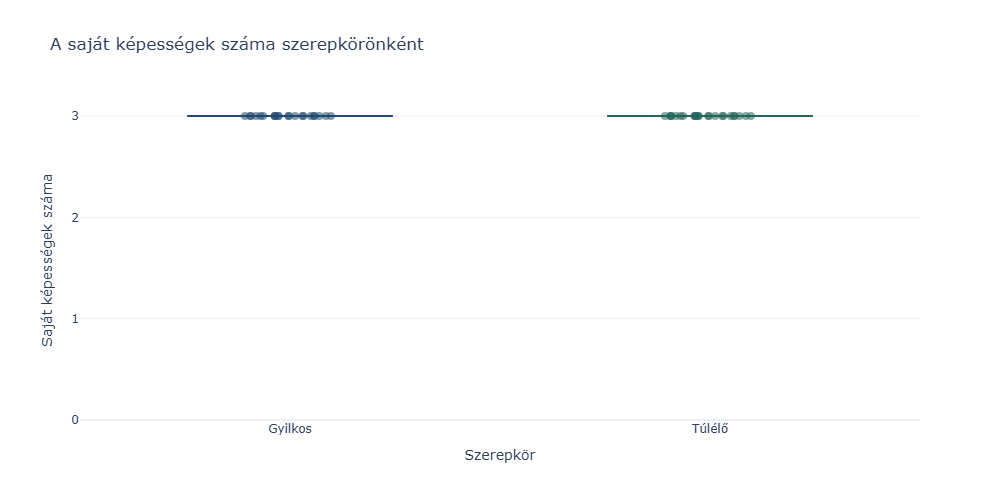

In [4]:
own_perks = perks_by_character[perks_by_character["Karakter"] != "Általános"]

boxplot = px.box(
    own_perks,
    x="Szerepkör",
    y="Darabszám",
    color="Szerepkör",
    points="all",
    color_discrete_map={"Gyilkos": "#234a70", "Túlélő": "#256559"},
    labels={"Darabszám": "Saját képességek száma"},
    title="A saját képességek száma szerepkörönként",
    template="plotly_white",
)
boxplot.update_traces(jitter=0.45, pointpos=0, marker=dict(size=8, opacity=0.55))
boxplot.update_yaxes(rangemode="tozero", dtick=1)
boxplot.update_layout(showlegend=False)
boxplot.show()

## Pályák

Hány különböző pálya tartozik az egyes realmekhez?

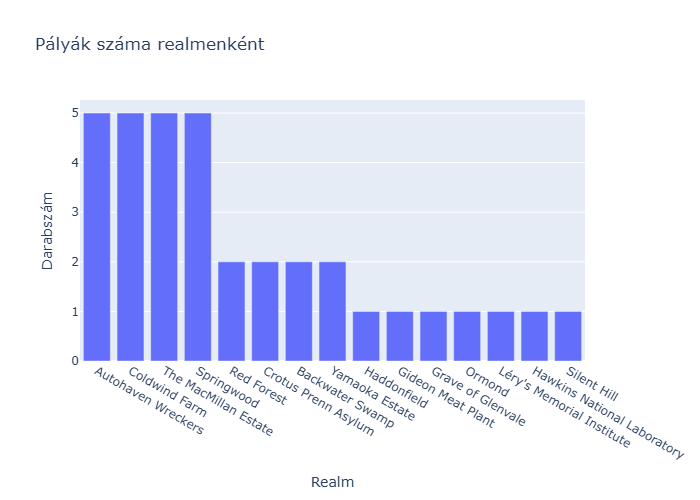

In [5]:
maps = read("maps")
realms = read("realms")
maps_by_realm = maps.groupby("realm")["map"].nunique().reindex(realms["realm"], fill_value=0)
maps_by_realm = maps_by_realm.sort_values(ascending=False).reset_index(name="Darabszám")
px.bar(maps_by_realm, x="realm", y="Darabszám", labels={"realm": "Realm"}, title="Pályák száma realmenként").show()

## Tárgyak és kiegészítők

A diagram ritkaság szerint mutatja a túlélők tárgyait, valamint a túlélők és a gyilkosok kiegészítőit.

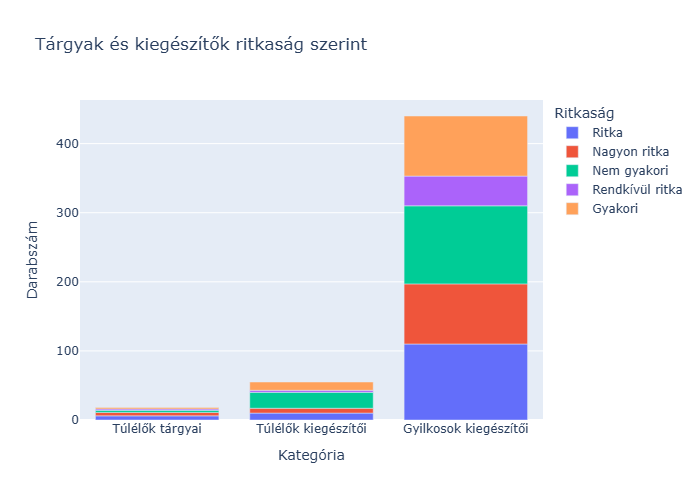

In [6]:
gear = pd.concat([
    counts(read("survivorItems"), "rarity", "Ritkaság").assign(Kategória="Túlélők tárgyai"),
    counts(read("survivorItemAddons"), "rarity", "Ritkaság").assign(Kategória="Túlélők kiegészítői"),
    counts(read("killerAddons"), "rarity", "Ritkaság").assign(Kategória="Gyilkosok kiegészítői"),
], ignore_index=True)
px.bar(gear, x="Kategória", y="Darabszám", title="Tárgyak és kiegészítők ritkaság szerint", color="Ritkaság").show()

## Felajánlások

A diagram a felajánlások számát szerepkör és ritkaság szerint mutatja. Egy felajánlás mindkét szerepkörnél szerepelhet.

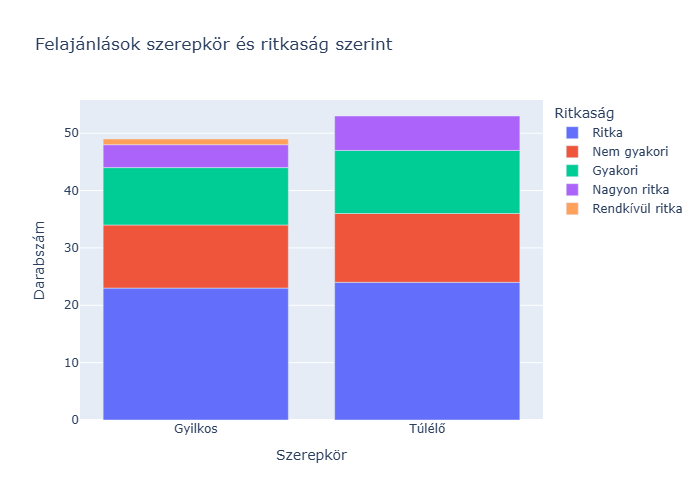

In [7]:
offerings = pd.concat([
    counts(read("killerOfferings"), "rarity", "Ritkaság").assign(Szerepkör="Gyilkos"),
    counts(read("survivorOfferings"), "rarity", "Ritkaság").assign(Szerepkör="Túlélő"),
], ignore_index=True)
px.bar(offerings, x="Szerepkör", y="Darabszám", title="Felajánlások szerepkör és ritkaság szerint", color="Ritkaság").show()

### 3. feladat – A felajánlások kereszttáblája

A táblázat ritkaságonként mutatja a gyilkosok és a túlélők felajánlásainak darabszámát. Ha egy szerepkörnél nincs felajánlás az adott ritkaságban, a táblázatban 0 szerepel.

In [8]:
offerings_pivot = offerings.pivot_table(
    index="Ritkaság",
    columns="Szerepkör",
    values="Darabszám",
    aggfunc="sum",
    fill_value=0,
)
offerings_pivot = offerings_pivot.reindex(RARITIES.values(), fill_value=0)
offerings_pivot

Szerepkör,Gyilkos,Túlélő
Ritkaság,,
Gyakori,10,11
Nem gyakori,11,12
Ritka,23,24
Nagyon ritka,4,6
Rendkívül ritka,1,0


## Tárgyak, kiegészítők és felajánlások hierarchikus eloszlása (treemap)

A diagram kategórián belül szerepkör, majd ritkaság szerint bontja az adatokat. A téglalap mérete a darabszámot mutatja. Kattints egy kategóriára a részletekhez. A mindkét szerepkörhöz tartozó felajánlások mindkét ágon szerepelnek.

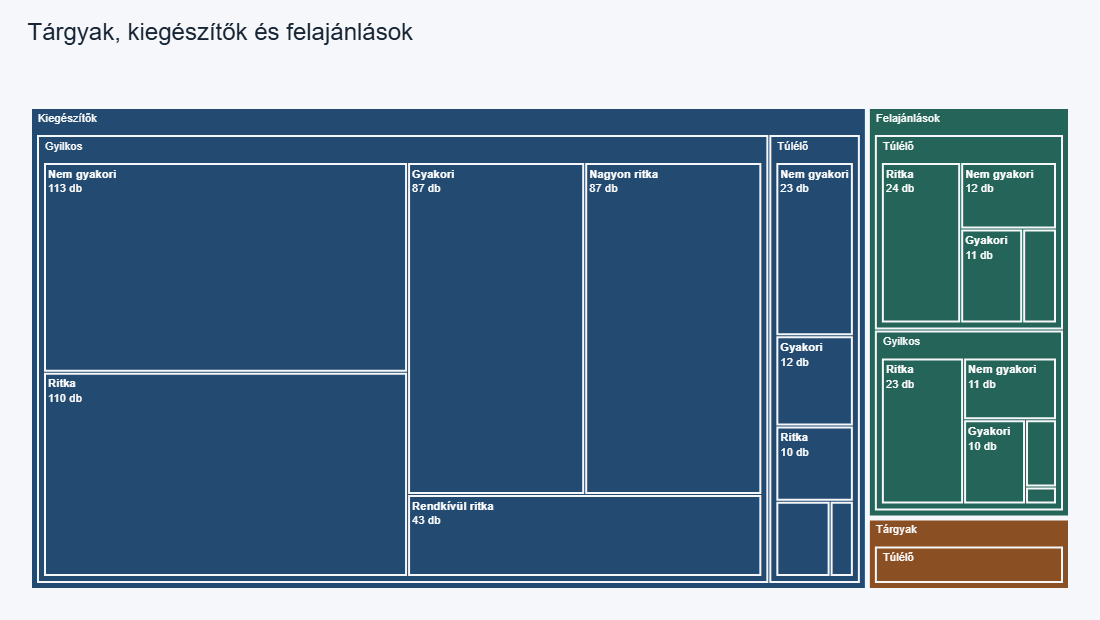

In [9]:
gear_groups = pd.DataFrame([
    ("Túlélők tárgyai", "Tárgyak", "Túlélő"),
    ("Túlélők kiegészítői", "Kiegészítők", "Túlélő"),
    ("Gyilkosok kiegészítői", "Kiegészítők", "Gyilkos"),
], columns=["Kategória", "Típus", "Szerepkör"])

treemap_data = pd.concat([
    gear.merge(gear_groups, on="Kategória"),
    offerings.assign(Típus="Felajánlások"),
], ignore_index=True)

treemap = px.treemap(
    treemap_data,
    path=["Típus", "Szerepkör", "Ritkaság"],
    values="Darabszám",
    color="Típus",
    color_discrete_map={
        "Tárgyak": "#8b4f24",
        "Kiegészítők": "#234a70",
        "Felajánlások": "#256559",
    },
    title="Tárgyak, kiegészítők és felajánlások",
)
treemap.update_traces(
    marker_line_color="#f5f7fa",
    marker_line_width=2,
    tiling_pad=3,
    texttemplate="<b>%{label}</b><br>%{value} db",
    hovertemplate="<b>%{label}</b><br>%{value} db<br>A csoporton belül: %{percentParent:.1%}<extra></extra>",
)
treemap.update_layout(
    template="plotly_white",
    paper_bgcolor="#f5f7fa",
    font=dict(family="Arial, sans-serif", size=14, color="#172535"),
    title=dict(x=0.025, font_size=24),
    margin=dict(t=80, l=24, r=24, b=24),
    height=620,
    uniformtext=dict(minsize=10, mode="hide"),
)
treemap.show()